In [1]:
# ==============================================================================
# SECTION 01: ENVIRONMENT SETUP, DATA LOADING & METHODOLOGICAL FILTERING
# What we are doing:
#   1. Import core data analysis (pandas, numpy) and visualization (matplotlib, seaborn) packages.
#   2. Configure consistent chart styling to match our analytical design.
#   3. Load the raw dataset (119,390 bookings, 32 columns) from your local path.
#   4. Construct exact calendar arrival dates and derive booking dates (arrival_date - lead_time).
#   5. Filter to honoured stays only (reservation_status == "Check-Out", n = 75,166),
#      excluding cancellations (43,017) and no-shows (1,207).
# ==============================================================================

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns

# Configure clean publication-grade plot styling
plt.style.use("default")
sns.set_style("whitegrid")
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["font.size"] = 10.5
plt.rcParams["axes.titlesize"] = 12.5
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 10.5
plt.rcParams["axes.edgecolor"] = "#d0d7de"
plt.rcParams["grid.color"] = "#eaedf2"
plt.rcParams["grid.linewidth"] = 0.8

# Color palette
NAVY = "#14213d"
TEAL = "#136f63"
AMBER = "#e08e26"
CRIMSON = "#9e2a2b"
SLATE = "#647284"

# Load dataset from your local path
file_path = r"C:\Users\ngosa\Desktop\GITHUB ROADMAP\Hotel Revenue forcasting Model\hotel_bookings demand.csv"
df = pd.read_csv(file_path)

# Construct exact arrival date and derive booking date
df["arrival_date"] = pd.to_datetime(
    df["arrival_date_year"].astype(str)
    + "-"
    + df["arrival_date_month"].astype(str)
    + "-"
    + df["arrival_date_day_of_month"].astype(str)
)
df["booking_date"] = df["arrival_date"] - pd.to_timedelta(
    df["lead_time"], unit="D"
)

# Filter to honoured bookings only (Check-Out)
status_counts = df["reservation_status"].value_counts()
df_stayed = df[df["reservation_status"] == "Check-Out"].copy()

# Verify Section 01 dataset summary metrics
print("--- SECTION 01: DATASET & METHOD SUMMARY ---")
print(
    f"Raw records loaded      : {len(df):,} rows x"
    f" {df.shape[1] - 2} original columns"
)
print(f"Check-Out (stayed)      : {status_counts['Check-Out']:,}")
print(f"Canceled (excluded)     : {status_counts['Canceled']:,}")
print(f"No-Show (excluded)      : {status_counts['No-Show']:,}")
print(
    "Arrival date span       :"
    f" {df_stayed['arrival_date'].min().strftime('%d %b %Y')} to"
    f" {df_stayed['arrival_date'].max().strftime('%d %b %Y')}"
)
print(
    f"Hotels included         : {df_stayed['hotel'].value_counts().to_dict()}"
)

--- SECTION 01: DATASET & METHOD SUMMARY ---
Raw records loaded      : 119,390 rows x 32 original columns
Check-Out (stayed)      : 75,166
Canceled (excluded)     : 43,017
No-Show (excluded)      : 1,207
Arrival date span       : 01 Jul 2015 to 31 Aug 2017
Hotels included         : {'City Hotel': 46228, 'Resort Hotel': 28938}


--- SECTION 02: BOOKING WINDOW SUMMARY ---
Stayed bookings analysed : 75,166
Median lead time         : 45 days
Mean lead time           : 80.0 days
Same-day bookings        : 5,915 (7.9%)
Longest booking window   : 737 days

--- CUMULATIVE SHARE MILESTONES ---
Within 7 days            : 23.7%
Within 30 days           : 41.9%
Within 60 days           : 56.3%
Within 90 days           : 66.4%
Within 180 days          : 85.9%
Within 365 days          : 98.6%
More than 180 days       : 14.1%


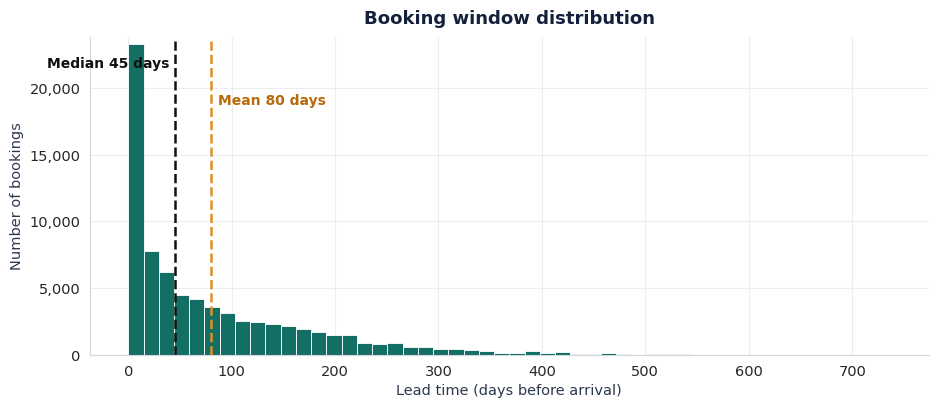

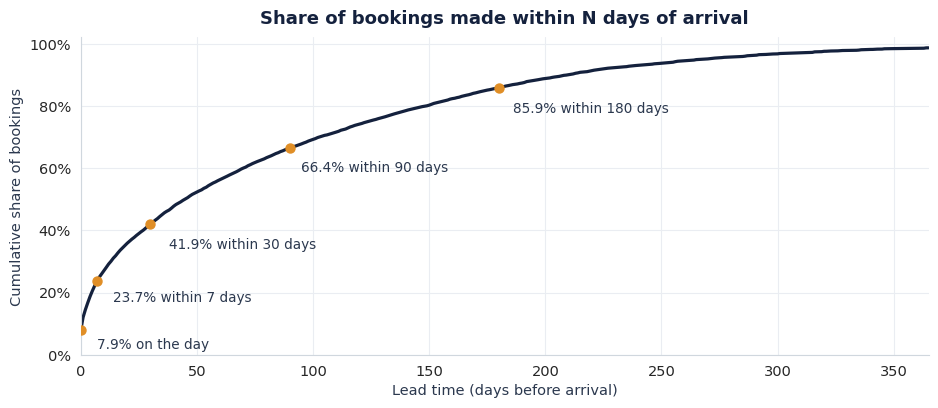

In [2]:
# ==============================================================================
# SECTION 02: BOOKING WINDOW ANALYSIS & CUMULATIVE DISTRIBUTION
# What we are doing:
#   1. Compute core booking window metrics across all 75,166 stayed bookings:
#      median lead time (45 days), mean lead time (80 days), same-day bookings
#      (5,915 / 7.9%), and maximum booking window (737 days).
#   2. Calculate exact cumulative booking shares at key thresholds:
#      within 7 days (23.7%), 30 days (41.9%), 60 days (56.3%), 90 days (66.4%),
#      180 days (85.9%), 365 days (98.6%), and >180 days (14.1%).
#   3. Generate Figure 1: 50-bin histogram of lead time with Median & Mean markers.
#   4. Generate Figure 2: Cumulative share curve (0 to 365 days) with amber milestone dots.
# ==============================================================================

# 1. Core Summary Statistics
n_stayed = len(df_stayed)
median_lt = df_stayed["lead_time"].median()
mean_lt = df_stayed["lead_time"].mean()
same_day_n = (df_stayed["lead_time"] == 0).sum()
same_day_pct = (df_stayed["lead_time"] == 0).mean() * 100
max_lt = df_stayed["lead_time"].max()

# 2. Cumulative Milestone Shares
within_7 = (df_stayed["lead_time"] <= 7).mean() * 100
within_30 = (df_stayed["lead_time"] <= 30).mean() * 100
within_60 = (df_stayed["lead_time"] <= 60).mean() * 100
within_90 = (df_stayed["lead_time"] <= 90).mean() * 100
within_180 = (df_stayed["lead_time"] <= 180).mean() * 100
within_365 = (df_stayed["lead_time"] <= 365).mean() * 100
over_180 = (df_stayed["lead_time"] > 180).mean() * 100

print("--- SECTION 02: BOOKING WINDOW SUMMARY ---")
print(f"Stayed bookings analysed : {n_stayed:,}")
print(f"Median lead time         : {median_lt:.0f} days")
print(f"Mean lead time           : {mean_lt:.1f} days")
print(f"Same-day bookings        : {same_day_n:,} ({same_day_pct:.1f}%)")
print(f"Longest booking window   : {max_lt:,} days")
print("\n--- CUMULATIVE SHARE MILESTONES ---")
print(f"Within 7 days            : {within_7:.1f}%")
print(f"Within 30 days           : {within_30:.1f}%")
print(f"Within 60 days           : {within_60:.1f}%")
print(f"Within 90 days           : {within_90:.1f}%")
print(f"Within 180 days          : {within_180:.1f}%")
print(f"Within 365 days          : {within_365:.1f}%")
print(f"More than 180 days       : {over_180:.1f}%")

# 3. Figure 1: Booking window distribution (50 bins)
fig1, ax1 = plt.subplots(figsize=(9.5, 4.2))
ax1.hist(
    df_stayed["lead_time"],
    bins=50,
    color=TEAL,
    edgecolor="white",
    linewidth=0.6,
)
ax1.axvline(median_lt, color="#111111", linestyle="--", linewidth=1.8)
ax1.axvline(mean_lt, color=AMBER, linestyle="--", linewidth=1.8)

ax1.text(
    median_lt - 5,
    22400,
    f"Median {int(median_lt)} days",
    ha="right",
    va="top",
    fontsize=10,
    fontweight="bold",
    color="#111111",
)
ax1.text(
    mean_lt + 7,
    19600,
    f"Mean {mean_lt:.0f} days",
    ha="left",
    va="top",
    fontsize=10,
    fontweight="bold",
    color="#b86b0d",
)

ax1.set_title(
    "Booking window distribution",
    fontsize=13,
    fontweight="bold",
    color=NAVY,
    pad=10,
)
ax1.set_xlabel("Lead time (days before arrival)", fontsize=10.5, color="#2b384e")
ax1.set_ylabel("Number of bookings", fontsize=10.5, color="#2b384e")
ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax1.set_ylim(0, 23800)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("figure1_booking_window_distribution.png", dpi=300)
plt.show()

# 4. Figure 2: Share of bookings made within N days of arrival (0 to 365 days)
days_grid = np.arange(0, 366)
cum_shares = [(df_stayed["lead_time"] <= d).mean() * 100 for d in days_grid]

fig2, ax2 = plt.subplots(figsize=(9.5, 4.2))
ax2.plot(days_grid, cum_shares, color=NAVY, linewidth=2.3)

milestones = [
    (0, same_day_pct, f"{same_day_pct:.1f}% on the day", (7, 2)),
    (7, within_7, f"{within_7:.1f}% within 7 days", (14, 17)),
    (30, within_30, f"{within_30:.1f}% within 30 days", (38, 34)),
    (90, within_90, f"{within_90:.1f}% within 90 days", (95, 59)),
    (180, within_180, f"{within_180:.1f}% within 180 days", (186, 78)),
]

for d_val, pct_val, label_txt, text_pos in milestones:
  ax2.scatter([d_val], [pct_val], color=AMBER, s=42, zorder=5)
  ax2.text(text_pos[0], text_pos[1], label_txt, fontsize=9.8, color="#2b384e")

ax2.set_title(
    "Share of bookings made within N days of arrival",
    fontsize=13,
    fontweight="bold",
    color=NAVY,
    pad=10,
)
ax2.set_xlabel("Lead time (days before arrival)", fontsize=10.5, color="#2b384e")
ax2.set_ylabel("Cumulative share of bookings", fontsize=10.5, color="#2b384e")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax2.set_xlim(0, 365)
ax2.set_ylim(0, 102)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("figure2_cumulative_booking_share.png", dpi=300)
plt.show()

--- SECTION 03: BUSIEST ARRIVAL DATE SUMMARY ---
Busiest arrival date     : 05 Dec 2015 (255 stayed bookings)
Median lead time         : 19 days (vs 45 days for all bookings)
On the books >= 60 days  : 55 bookings (21.6% vs 44.1% overall)
On the books >= 30 days  : 117 bookings (45.9% vs 58.6% overall)
On the books >= 7 days   : 208 bookings (final week adds 47 bookings)

--- MAJOR SINGLE-DAY BLOCK STEPS (05 DEC 2015) ---
135 days out : 29 bookings | Segments: {'Groups': 29} | Hotels: {'City Hotel': 29}
 47 days out : 29 bookings | Segments: {'Groups': 28, 'Offline TA/TO': 1} | Hotels: {'City Hotel': 28, 'Resort Hotel': 1}
 11 days out : 42 bookings | Segments: {'Groups': 41, 'Direct': 1} | Hotels: {'Resort Hotel': 26, 'City Hotel': 16}


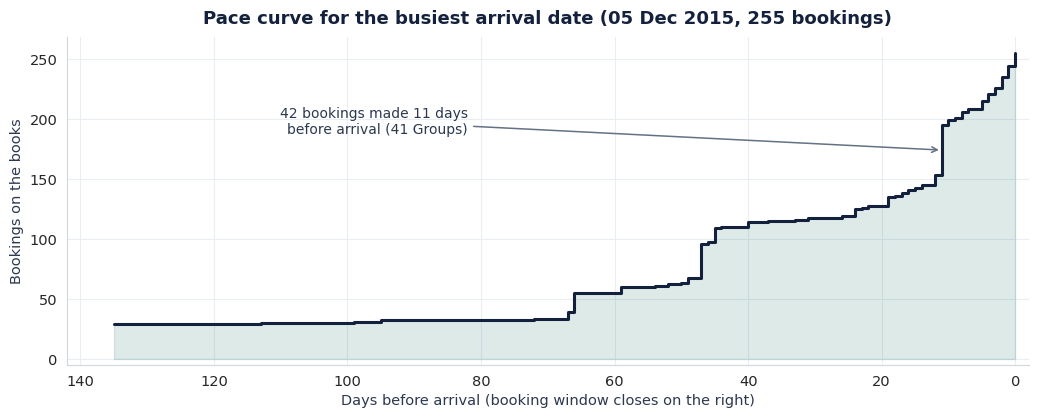

In [3]:
# ==============================================================================
# SECTION 03: PACE CURVE OF THE BUSIEST ARRIVAL DATE (05 DEC 2015)
# What we are doing:
#   1. Identify the single busiest arrival date across all 75,166 stayed bookings
#      (05 Dec 2015 with 255 stayed bookings).
#   2. Compute the busiest date's median lead time (19 days vs 45 days overall).
#   3. Calculate cumulative On-The-Books (OTB) shares at 60 days out (21.6% vs 44.1%
#      overall), 30 days out (45.9% vs 58.6% overall), and 7 days out (208 bookings).
#   4. Inspect the three major single-day block surges: 135 days out (29 bookings),
#      47 days out (29 bookings), and 11 days out (42 bookings).
#   5. Plot Figure 3: Cumulative step pace curve from 135 days before arrival down
#      to arrival day (0), with shaded area and block-surge callout annotation.
# ==============================================================================

# 1. Identify busiest arrival date and filter stayed bookings
busiest_date = df_stayed.groupby("arrival_date").size().idxmax()
df_peak = df_stayed[df_stayed["arrival_date"] == busiest_date].copy()

peak_total = len(df_peak)
peak_median_lt = df_peak["lead_time"].median()
overall_median_lt = df_stayed["lead_time"].median()

# 2. On-The-Books (OTB) comparison vs full stayed dataset
otb_60_n = (df_peak["lead_time"] >= 60).sum()
otb_60_pct = (df_peak["lead_time"] >= 60).mean() * 100
overall_60_pct = (df_stayed["lead_time"] >= 60).mean() * 100

otb_30_n = (df_peak["lead_time"] >= 30).sum()
otb_30_pct = (df_peak["lead_time"] >= 30).mean() * 100
overall_30_pct = (df_stayed["lead_time"] >= 30).mean() * 100

otb_7_n = (df_peak["lead_time"] >= 7).sum()
final_week_pickup = peak_total - otb_7_n

print("--- SECTION 03: BUSIEST ARRIVAL DATE SUMMARY ---")
print(
    f"Busiest arrival date     : {busiest_date.strftime('%d %b %Y')} "
    f"({peak_total} stayed bookings)"
)
print(
    f"Median lead time         : {peak_median_lt:.0f} days "
    f"(vs {overall_median_lt:.0f} days for all bookings)"
)
print(
    f"On the books >= 60 days  : {otb_60_n} bookings ({otb_60_pct:.1f}% vs"
    f" {overall_60_pct:.1f}% overall)"
)
print(
    f"On the books >= 30 days  : {otb_30_n} bookings ({otb_30_pct:.1f}% vs"
    f" {overall_30_pct:.1f}% overall)"
)
print(
    f"On the books >= 7 days   : {otb_7_n} bookings (final week adds"
    f" {final_week_pickup} bookings)"
)

print("\n--- MAJOR SINGLE-DAY BLOCK STEPS (05 DEC 2015) ---")
for lt in [135, 47, 11]:
  sub_block = df_peak[df_peak["lead_time"] == lt]
  segs = sub_block["market_segment"].value_counts().to_dict()
  hotels = sub_block["hotel"].value_counts().to_dict()
  print(
      f"{lt:>3} days out : {len(sub_block):>2} bookings | Segments: {segs} |"
      f" Hotels: {hotels}"
  )

# 3. Figure 3: Cumulative Bookings on the Books Pace Curve
max_lt_peak = int(df_peak["lead_time"].max())
days_out = np.arange(max_lt_peak, -1, -1)
cum_otb = [(df_peak["lead_time"] >= d).sum() for d in days_out]

fig3, ax3 = plt.subplots(figsize=(10.5, 4.3))

ax3.step(days_out, cum_otb, where="post", color=NAVY, linewidth=2.2)
ax3.fill_between(days_out, cum_otb, step="post", color=TEAL, alpha=0.14)

# Time progresses from 140 days out on the left to arrival day (0) on the right
ax3.set_xlim(142, -2)
ax3.set_ylim(-5, 268)

ax3.set_title(
    "Pace curve for the busiest arrival date (05 Dec 2015, 255 bookings)",
    fontsize=13,
    fontweight="bold",
    color=NAVY,
    pad=10,
)
ax3.set_xlabel(
    "Days before arrival (booking window closes on the right)",
    fontsize=10.5,
    color="#2b384e",
)
ax3.set_ylabel("Bookings on the books", fontsize=10.5, color="#2b384e")

# Callout arrow pointing to the 42-booking jump at 11 days before arrival
ax3.annotate(
    "42 bookings made 11 days\nbefore arrival (41 Groups)",
    xy=(11, 174),
    xytext=(82, 198),
    ha="right",
    va="center",
    fontsize=10,
    color="#2b384e",
    arrowprops=dict(arrowstyle="->", color="#647284", lw=1.1),
)

ax3.spines["top"].set_visible(False)
ax3.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("figure3_busiest_date_pace_curve.png", dpi=300)
plt.show()

--- SECTION 04: AUGUST 2017 PICKUP SUMMARY ---
August 2017 stayed bookings : 3,109 (City 2,002, Resort 1,107)
Daily average bookings      : 100.3 (range: 62 to 147)
Booked within 3 days        : 11.2% | Within 7 days: 15.0% | Within 120 days: 51.4%

--- TOP HEATMAP CELLS (>= 10 BOOKINGS WITHIN 120 DAYS) ---
24 Aug at   2 days out : 14 bookings | Segments: {'Groups': 11, 'Direct': 2, 'Online TA': 1} | Hotels: {'City Hotel': 14}
03 Aug at   2 days out : 12 bookings | Segments: {'Groups': 8, 'Online TA': 3, 'Corporate': 1} | Hotels: {'City Hotel': 11, 'Resort Hotel': 1}
27 Aug at   0 days out : 12 bookings | Segments: {'Online TA': 7, 'Direct': 5} | Hotels: {'City Hotel': 7, 'Resort Hotel': 5}
15 Aug at   0 days out : 11 bookings | Segments: {'Direct': 5, 'Online TA': 5, 'Complementary': 1} | Hotels: {'Resort Hotel': 8, 'City Hotel': 3}
20 Aug at 115 days out : 10 bookings | Segments: {'Offline TA/TO': 10} | Hotels: {'City Hotel': 10}


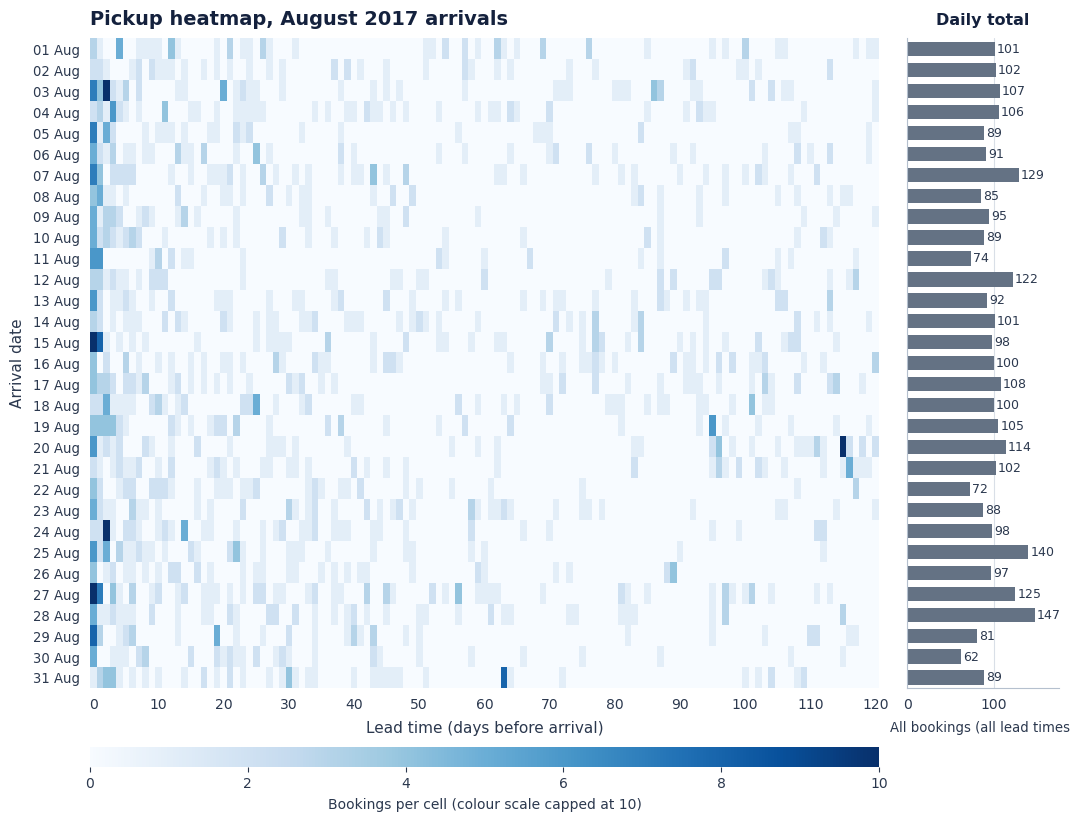

In [4]:
# ==============================================================================
# SECTION 04: PICKUP HEATMAP, AUGUST 2017 ARRIVALS
# What we are doing:
#   1. Filter stayed bookings to August 2017 arrivals (n = 3,109: 2,002 City Hotel,
#      1,107 Resort Hotel).
#   2. Compute daily booking volume statistics across all 31 arrival dates
#      (mean 100.3 bookings/day, min 62, max 147) and cumulative lead-time shares
#      (11.2% within 3 days, 15.0% within 7 days, 51.4% within 120 days).
#   3. Build the 31 x 121 pickup pivot matrix (01 Aug to 31 Aug x lead times 0 to
#      120 days) and inspect the five cells reaching 10 or more bookings.
#   4. Plot Figure 4: Pickup heatmap (colour scale capped at 10) paired with an
#      aligned horizontal bar chart showing each arrival date's total bookings
#      across all lead times.
# ==============================================================================

# 1. Filter August 2017 stayed arrivals
aug17 = df_stayed[
    (df_stayed["arrival_date_year"] == 2017)
    & (df_stayed["arrival_date_month"] == "August")
].copy()

all_aug_dates = pd.date_range("2017-08-01", "2017-08-31", freq="D")
daily_totals = (
    aug17.groupby("arrival_date").size().reindex(all_aug_dates, fill_value=0)
)

# 2. Summary statistics
total_aug17 = len(aug17)
city_aug17 = (aug17["hotel"] == "City Hotel").sum()
resort_aug17 = (aug17["hotel"] == "Resort Hotel").sum()
pct_3d = (aug17["lead_time"] <= 3).mean() * 100
pct_7d = (aug17["lead_time"] <= 7).mean() * 100
pct_120d = (aug17["lead_time"] <= 120).mean() * 100

print("--- SECTION 04: AUGUST 2017 PICKUP SUMMARY ---")
print(
    f"August 2017 stayed bookings : {total_aug17:,} "
    f"(City {city_aug17:,}, Resort {resort_aug17:,})"
)
print(
    f"Daily average bookings      : {daily_totals.mean():.1f} "
    f"(range: {daily_totals.min()} to {daily_totals.max()})"
)
print(
    f"Booked within 3 days        : {pct_3d:.1f}% | "
    f"Within 7 days: {pct_7d:.1f}% | Within 120 days: {pct_120d:.1f}%"
)

# 3. Build 31 x 121 pickup pivot matrix (lead times 0 to 120 days)
aug17_120 = aug17[aug17["lead_time"] <= 120]
heatmap_matrix = (
    aug17_120.groupby(["arrival_date", "lead_time"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=all_aug_dates, columns=np.arange(0, 121), fill_value=0)
)

print("\n--- TOP HEATMAP CELLS (>= 10 BOOKINGS WITHIN 120 DAYS) ---")
top_cells = []
for dt in all_aug_dates:
  for lt in range(121):
    val = int(heatmap_matrix.loc[dt, lt])
    if val >= 10:
      sub = aug17_120[
          (aug17_120["arrival_date"] == dt) & (aug17_120["lead_time"] == lt)
      ]
      segs = sub["market_segment"].value_counts().to_dict()
      hotels = sub["hotel"].value_counts().to_dict()
      top_cells.append((dt.strftime("%d %b"), lt, val, segs, hotels))

for dt_str, lt, val, segs, hotels in sorted(top_cells, key=lambda x: -x[2]):
  print(
      f"{dt_str} at {lt:>3} days out : {val:>2} bookings | Segments: {segs} |"
      f" Hotels: {hotels}"
  )

# 4. Figure 4: Pickup Heatmap + Aligned Daily Total Marginal Bar Chart
fig4 = plt.figure(figsize=(12.5, 9.5))
gs = fig4.add_gridspec(1, 2, width_ratios=[5.2, 1.0], wspace=0.06)
ax_hm = fig4.add_subplot(gs[0])
ax_bar = fig4.add_subplot(gs[1])

im = ax_hm.imshow(
    heatmap_matrix.values,
    aspect="auto",
    cmap="Blues",
    vmin=0,
    vmax=10,
    interpolation="nearest",
)

ax_hm.set_title(
    "Pickup heatmap, August 2017 arrivals",
    loc="left",
    fontsize=14,
    fontweight="bold",
    color=NAVY,
    pad=10,
)
ax_hm.set_xlabel(
    "Lead time (days before arrival)", fontsize=11, color="#2b384e", labelpad=6
)
ax_hm.set_ylabel("Arrival date", fontsize=11, color="#2b384e", labelpad=6)

xticks = np.arange(0, 121, 10)
ax_hm.set_xticks(xticks)
ax_hm.set_xticklabels(xticks, fontsize=10, color="#2b384e")
ax_hm.set_xlim(-0.5, 120.5)

yticks = np.arange(len(all_aug_dates))
ylabels = [d.strftime("%d %b") for d in all_aug_dates]
ax_hm.set_yticks(yticks)
ax_hm.set_yticklabels(ylabels, fontsize=9.5, color="#2b384e")
ax_hm.grid(False)
for spine in ax_hm.spines.values():
  spine.set_visible(False)

# Horizontal colorbar at bottom
cbar = fig4.colorbar(
    im,
    ax=ax_hm,
    orientation="horizontal",
    fraction=0.032,
    pad=0.08,
    aspect=38,
)
cbar.set_label(
    "Bookings per cell (colour scale capped at 10)",
    fontsize=10,
    color="#2b384e",
    labelpad=5,
)
cbar.set_ticks([0, 2, 4, 6, 8, 10])
cbar.ax.tick_params(labelsize=10, colors="#2b384e")
cbar.outline.set_visible(False)

# Right panel: Daily total horizontal bars (all lead times)
y_pos = np.arange(len(all_aug_dates))
ax_bar.barh(
    y_pos, daily_totals.values, height=0.68, color=SLATE, edgecolor="none"
)
ax_bar.set_ylim(len(all_aug_dates) - 0.5, -0.5)
ax_bar.set_xlim(0, 175)
ax_bar.set_xticks([0, 100])
ax_bar.set_xticklabels(["0", "100"], fontsize=10, color="#2b384e")
ax_bar.set_yticks(y_pos)
ax_bar.set_yticklabels([])
ax_bar.set_title(
    "Daily total", fontsize=11.5, fontweight="bold", color=NAVY, pad=10
)
ax_bar.set_xlabel(
    "All bookings (all lead times)", fontsize=9.5, color="#2b384e", labelpad=6
)

ax_bar.xaxis.grid(True, color="#d9dfe7", linestyle="-", linewidth=0.8)
ax_bar.yaxis.grid(False)
ax_bar.set_axisbelow(True)
ax_bar.spines["top"].set_visible(False)
ax_bar.spines["right"].set_visible(False)
ax_bar.spines["left"].set_color("#b5c0ce")
ax_bar.spines["bottom"].set_color("#b5c0ce")

for i, val in enumerate(daily_totals.values):
  ax_bar.text(
      val + 2.5, i, str(val), va="center", ha="left", fontsize=9, color="#2b384e"
  )

# Align bar chart row heights exactly with heatmap rows after colorbar layout
fig4.canvas.draw()
hm_pos = ax_hm.get_position()
bar_pos = ax_bar.get_position()
ax_bar.set_position([bar_pos.x0, hm_pos.y0, bar_pos.width, hm_pos.height])

plt.savefig("figure4_pickup_heatmap_august_2017.png", dpi=300, bbox_inches="tight")
plt.show()

--- SECTION 05: CITY HOTEL VS RESORT HOTEL METRICS ---
City Hotel share of stayed bookings: 61.5%

Hotel              City Hotel Resort Hotel
Metric                                    
Stayed bookings        46,228       28,938
Median lead time      50 days      38 days
Mean lead time      80.7 days    78.8 days
Same-day bookings        6.1%        10.6%
Within 7 days           20.5%        28.9%
Within 30 days          39.3%        46.2%
Within 90 days          66.3%        66.6%
More than 180 days      13.2%        15.6%
Average ADR         EUR 105.7     EUR 90.8


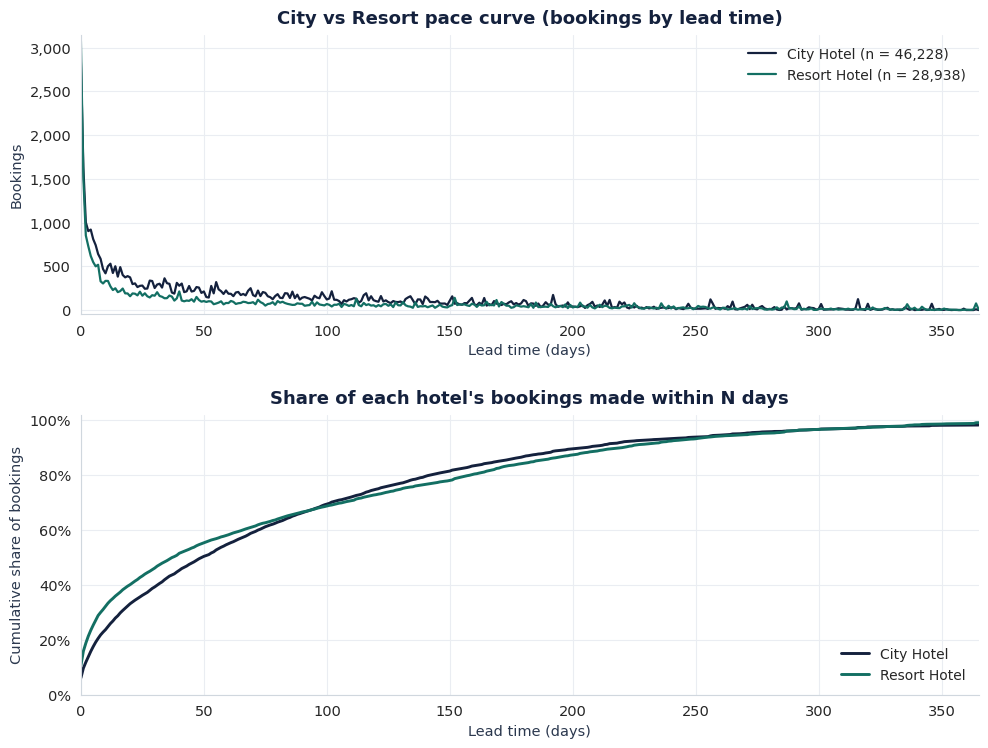

In [5]:
# ==============================================================================
# SECTION 05: CITY HOTEL VS RESORT HOTEL PACE & COMPARISON TABLE
# What we are doing:
#   1. Split stayed bookings between City Hotel (n = 46,228, 61.5% share) and
#      Resort Hotel (n = 28,938, 38.5% share).
#   2. Build the exact comparison pivot table across 9 metrics: Stayed bookings,
#      Median lead time, Mean lead time, Same-day bookings, Within 7 days,
#      Within 30 days, Within 90 days, More than 180 days, and Average ADR.
#   3. Plot Figure 5 (two stacked panels up to 365 days):
#      - Top: Raw booking counts by lead time (City Hotel in Navy, Resort in Teal).
#      - Bottom: Cumulative share of each hotel's own bookings made within N days.
# ==============================================================================

# 1. Build Section 05 Comparison Pivot Table
hotels = ["City Hotel", "Resort Hotel"]
summary_rows = []

for h in hotels:
  sub = df_stayed[df_stayed["hotel"] == h]
  summary_rows.append({
      "Hotel": h,
      "Stayed bookings": f"{len(sub):,}",
      "Median lead time": f"{sub['lead_time'].median():.0f} days",
      "Mean lead time": f"{sub['lead_time'].mean():.1f} days",
      "Same-day bookings": f"{(sub['lead_time'] == 0).mean() * 100:.1f}%",
      "Within 7 days": f"{(sub['lead_time'] <= 7).mean() * 100:.1f}%",
      "Within 30 days": f"{(sub['lead_time'] <= 30).mean() * 100:.1f}%",
      "Within 90 days": f"{(sub['lead_time'] <= 90).mean() * 100:.1f}%",
      "More than 180 days": f"{(sub['lead_time'] > 180).mean() * 100:.1f}%",
      "Average ADR": f"EUR {sub['adr'].mean():.1f}",
  })

df_sec05_table = pd.DataFrame(summary_rows).set_index("Hotel").T
df_sec05_table.index.name = "Metric"

city_share = (df_stayed["hotel"] == "City Hotel").mean() * 100

print("--- SECTION 05: CITY HOTEL VS RESORT HOTEL METRICS ---")
print(f"City Hotel share of stayed bookings: {city_share:.1f}%\n")
print(df_sec05_table.to_string())

# 2. Prepare daily counts & cumulative shares (0 to 365 days)
days_grid = np.arange(0, 366)
city_sub = df_stayed[df_stayed["hotel"] == "City Hotel"]
resort_sub = df_stayed[df_stayed["hotel"] == "Resort Hotel"]

city_counts = (
    city_sub["lead_time"].value_counts().reindex(days_grid, fill_value=0)
)
resort_counts = (
    resort_sub["lead_time"].value_counts().reindex(days_grid, fill_value=0)
)

city_cum = [(city_sub["lead_time"] <= d).mean() * 100 for d in days_grid]
resort_cum = [(resort_sub["lead_time"] <= d).mean() * 100 for d in days_grid]

# 3. Figure 5: Two-Panel City vs Resort Pace Curves
fig5, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(10.0, 7.6))

# Top Panel: Raw booking counts by lead time
ax_top.plot(
    days_grid,
    city_counts.values,
    color=NAVY,
    linewidth=1.6,
    label=f"City Hotel (n = {len(city_sub):,})",
)
ax_top.plot(
    days_grid,
    resort_counts.values,
    color=TEAL,
    linewidth=1.6,
    label=f"Resort Hotel (n = {len(resort_sub):,})",
)
ax_top.set_title(
    "City vs Resort pace curve (bookings by lead time)",
    fontsize=13,
    fontweight="bold",
    color=NAVY,
    pad=8,
)
ax_top.set_xlabel("Lead time (days)", fontsize=10.5, color="#2b384e")
ax_top.set_ylabel("Bookings", fontsize=10.5, color="#2b384e")
ax_top.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax_top.set_xlim(0, 365)
ax_top.set_ylim(-50, 3150)
ax_top.legend(loc="upper right", frameon=False, fontsize=10)
ax_top.spines["top"].set_visible(False)
ax_top.spines["right"].set_visible(False)

# Bottom Panel: Cumulative share of each hotel's own bookings
ax_bot.plot(days_grid, city_cum, color=NAVY, linewidth=2.1, label="City Hotel")
ax_bot.plot(
    days_grid, resort_cum, color=TEAL, linewidth=2.1, label="Resort Hotel"
)
ax_bot.set_title(
    "Share of each hotel's bookings made within N days",
    fontsize=13,
    fontweight="bold",
    color=NAVY,
    pad=8,
)
ax_bot.set_xlabel("Lead time (days)", fontsize=10.5, color="#2b384e")
ax_bot.set_ylabel("Cumulative share of bookings", fontsize=10.5, color="#2b384e")
ax_bot.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax_bot.set_xlim(0, 365)
ax_bot.set_ylim(0, 102)
ax_bot.legend(loc="lower right", frameon=False, fontsize=10)
ax_bot.spines["top"].set_visible(False)
ax_bot.spines["right"].set_visible(False)

plt.tight_layout(h_pad=2.2)
plt.savefig("figure5_city_vs_resort_pace.png", dpi=300)
plt.show()

--- SECTION 06: WEEKEND VS WEEKDAY ARRIVALS METRICS ---
Group              Weekend (Fri to Sun) Weekday (Mon to Thu)
Metric                                                      
Stayed bookings                  32,156               43,010
Median lead time                51 days              41 days
Mean lead time                82.2 days            78.3 days
Same-day bookings                  5.8%                 9.4%
Within 7 days                     20.0%                26.5%
Within 30 days                    39.0%                44.2%
More than 180 days                14.3%                14.0%


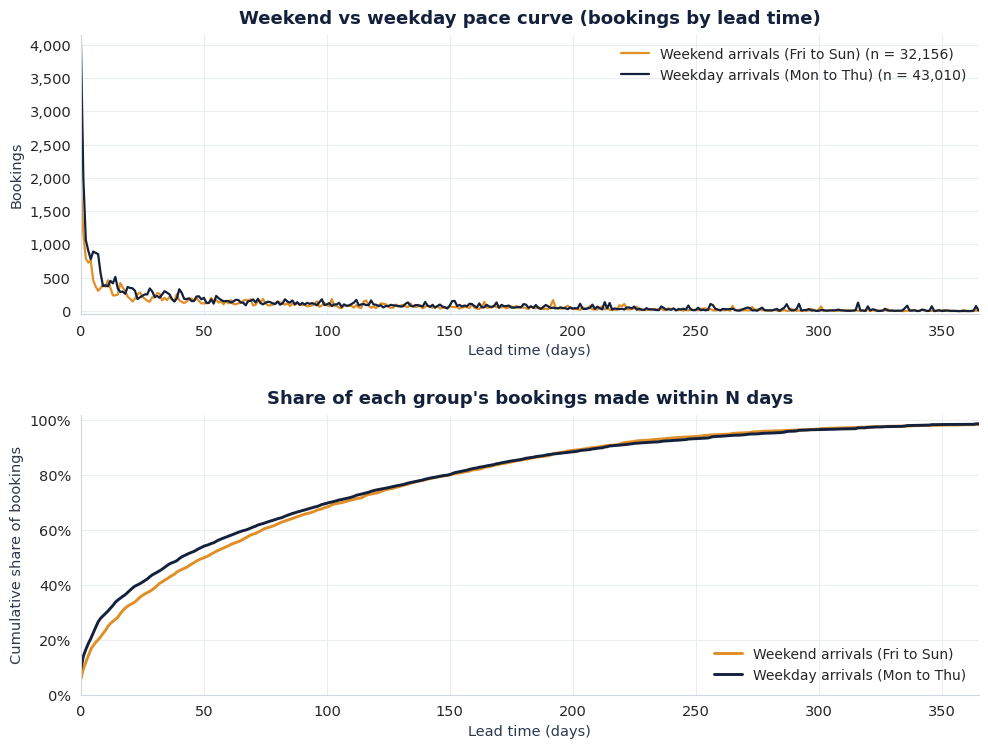

In [6]:
# ==============================================================================
# SECTION 06: WEEKEND VS WEEKDAY ARRIVALS PACE & COMPARISON TABLE
# What we are doing:
#   1. Classify stayed bookings by arrival day of week:
#      - Weekend arrivals (Fri to Sun): n = 32,156
#      - Weekday arrivals (Mon to Thu): n = 43,010
#   2. Build the exact comparison pivot table across 7 metrics: Stayed bookings,
#      Median lead time, Mean lead time, Same-day bookings, Within 7 days,
#      Within 30 days, and More than 180 days.
#   3. Plot Figure 6 (two stacked panels up to 365 days):
#      - Top: Raw booking counts by lead time (Weekend in Amber, Weekday in Navy).
#      - Bottom: Cumulative share of each group's own bookings made within N days.
# ==============================================================================

# 1. Classify arrival dates into Weekend (Fri-Sun) vs Weekday (Mon-Thu)
df_stayed["arrival_group"] = np.where(
    df_stayed["arrival_date"].dt.dayofweek.isin([4, 5, 6]),
    "Weekend (Fri to Sun)",
    "Weekday (Mon to Thu)",
)

# 2. Build Section 06 Comparison Pivot Table
groups = ["Weekend (Fri to Sun)", "Weekday (Mon to Thu)"]
summary_rows = []

for g in groups:
  sub = df_stayed[df_stayed["arrival_group"] == g]
  summary_rows.append({
      "Group": g,
      "Stayed bookings": f"{len(sub):,}",
      "Median lead time": f"{sub['lead_time'].median():.0f} days",
      "Mean lead time": f"{sub['lead_time'].mean():.1f} days",
      "Same-day bookings": f"{(sub['lead_time'] == 0).mean() * 100:.1f}%",
      "Within 7 days": f"{(sub['lead_time'] <= 7).mean() * 100:.1f}%",
      "Within 30 days": f"{(sub['lead_time'] <= 30).mean() * 100:.1f}%",
      "More than 180 days": f"{(sub['lead_time'] > 180).mean() * 100:.1f}%",
  })

df_sec06_table = pd.DataFrame(summary_rows).set_index("Group").T
df_sec06_table.index.name = "Metric"

print("--- SECTION 06: WEEKEND VS WEEKDAY ARRIVALS METRICS ---")
print(df_sec06_table.to_string())

# 3. Prepare daily counts & cumulative shares (0 to 365 days)
days_grid = np.arange(0, 366)
wknd_sub = df_stayed[df_stayed["arrival_group"] == "Weekend (Fri to Sun)"]
wkdy_sub = df_stayed[df_stayed["arrival_group"] == "Weekday (Mon to Thu)"]

wknd_counts = (
    wknd_sub["lead_time"].value_counts().reindex(days_grid, fill_value=0)
)
wkdy_counts = (
    wkdy_sub["lead_time"].value_counts().reindex(days_grid, fill_value=0)
)

wknd_cum = [(wknd_sub["lead_time"] <= d).mean() * 100 for d in days_grid]
wkdy_cum = [(wkdy_sub["lead_time"] <= d).mean() * 100 for d in days_grid]

# 4. Figure 6: Two-Panel Weekend vs Weekday Pace Curves
fig6, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(10.0, 7.6))

# Top Panel: Raw booking counts by lead time
ax_top.plot(
    days_grid,
    wknd_counts.values,
    color=AMBER,
    linewidth=1.6,
    label=f"Weekend arrivals (Fri to Sun) (n = {len(wknd_sub):,})",
)
ax_top.plot(
    days_grid,
    wkdy_counts.values,
    color=NAVY,
    linewidth=1.6,
    label=f"Weekday arrivals (Mon to Thu) (n = {len(wkdy_sub):,})",
)
ax_top.set_title(
    "Weekend vs weekday pace curve (bookings by lead time)",
    fontsize=13,
    fontweight="bold",
    color=NAVY,
    pad=8,
)
ax_top.set_xlabel("Lead time (days)", fontsize=10.5, color="#2b384e")
ax_top.set_ylabel("Bookings", fontsize=10.5, color="#2b384e")
ax_top.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax_top.set_xlim(0, 365)
ax_top.set_ylim(-50, 4150)
ax_top.legend(loc="upper right", frameon=False, fontsize=10)
ax_top.spines["top"].set_visible(False)
ax_top.spines["right"].set_visible(False)

# Bottom Panel: Cumulative share of each group's own bookings
ax_bot.plot(
    days_grid,
    wknd_cum,
    color=AMBER,
    linewidth=2.1,
    label="Weekend arrivals (Fri to Sun)",
)
ax_bot.plot(
    days_grid,
    wkdy_cum,
    color=NAVY,
    linewidth=2.1,
    label="Weekday arrivals (Mon to Thu)",
)
ax_bot.set_title(
    "Share of each group's bookings made within N days",
    fontsize=13,
    fontweight="bold",
    color=NAVY,
    pad=8,
)
ax_bot.set_xlabel("Lead time (days)", fontsize=10.5, color="#2b384e")
ax_bot.set_ylabel("Cumulative share of bookings", fontsize=10.5, color="#2b384e")
ax_bot.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax_bot.set_xlim(0, 365)
ax_bot.set_ylim(0, 102)
ax_bot.legend(loc="lower right", frameon=False, fontsize=10)
ax_bot.spines["top"].set_visible(False)
ax_bot.spines["right"].set_visible(False)

plt.tight_layout(h_pad=2.2)
plt.savefig("figure6_weekend_vs_weekday_pace.png", dpi=300)
plt.show()

--- SECTION 07: TOP 5 MARKET SEGMENTS PICKUP SUMMARY ---
Combined share of top 5 segments : 98.9%
Online TA share of all stays     : 47.5%

Online TA       | n = 35,738 | Median:  43d | Same-day:  5.5% | <=7d: 21.1% | >180d:  9.7%
Offline TA/TO   | n = 15,908 | Median:  90d | Same-day:  2.6% | <=7d: 11.2% | >180d: 24.4%
Direct          | n = 10,672 | Median:  11d | Same-day: 24.2% | <=7d: 45.3% | >180d:  5.9%
Groups          | n =  7,714 | Median: 107d | Same-day:  0.8% | <=7d:  7.3% | >180d: 33.6%
Corporate       | n =  4,303 | Median:   6d | Same-day: 15.6% | <=7d: 58.2% | >180d:  0.6%


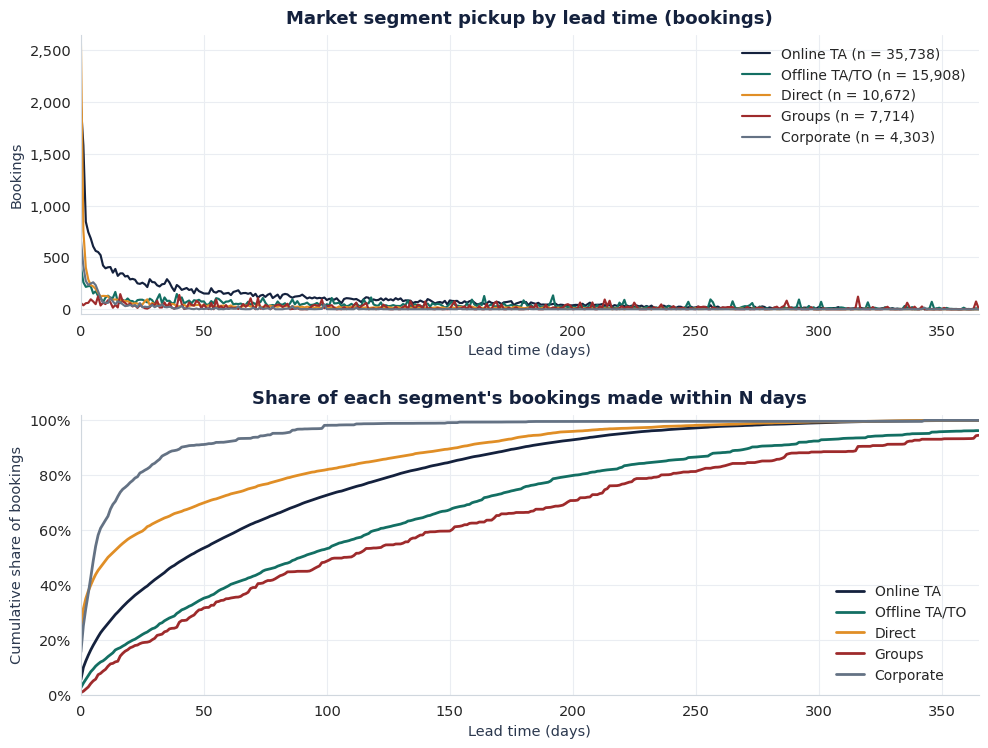

In [7]:
# ==============================================================================
# SECTION 07: MARKET SEGMENT PICKUP PACE CURVES (TOP 5 SEGMENTS)
# What we are doing:
#   1. Isolate the five largest market segments—Online TA (35,738), Offline TA/TO
#      (15,908), Direct (10,672), Groups (7,714), and Corporate (4,303)—which
#      together represent 98.9% of all 75,166 stayed bookings.
#   2. Compute key segment pace metrics: overall share (Online TA = 47.5%),
#      median lead times (90d Offline TA/TO, 107d Groups), same-day share
#      (24.2% Direct), within-7-day share (45.3% Direct, 58.2% Corporate), and
#      over-180-day share (24.4% Offline TA/TO, 33.6% Groups).
#   3. Plot Figure 7 (two stacked panels up to 365 days):
#      - Top: Raw booking counts by lead time across the top 5 segments.
#      - Bottom: Cumulative share of each segment's own bookings made within N days.
# ==============================================================================

# 1. Define top 5 segments and compute key Section 07 metrics
top_5_segments = ["Online TA", "Offline TA/TO", "Direct", "Groups", "Corporate"]
top_5_share = df_stayed["market_segment"].isin(top_5_segments).mean() * 100
online_ta_share = (df_stayed["market_segment"] == "Online TA").mean() * 100

print("--- SECTION 07: TOP 5 MARKET SEGMENTS PICKUP SUMMARY ---")
print(f"Combined share of top 5 segments : {top_5_share:.1f}%")
print(f"Online TA share of all stays     : {online_ta_share:.1f}%\n")

for seg in top_5_segments:
  sub = df_stayed[df_stayed["market_segment"] == seg]
  print(
      f"{seg:<15} | n = {len(sub):>6,} | "
      f"Median: {sub['lead_time'].median():>3.0f}d | "
      f"Same-day: {(sub['lead_time'] == 0).mean() * 100:>4.1f}% | "
      f"<=7d: {(sub['lead_time'] <= 7).mean() * 100:>4.1f}% | "
      f">180d: {(sub['lead_time'] > 180).mean() * 100:>4.1f}%"
  )

# 2. Figure 7: Two-Panel Market Segment Pickup Curves (0 to 365 days)
seg_colors = {
    "Online TA": NAVY,
    "Offline TA/TO": TEAL,
    "Direct": AMBER,
    "Groups": CRIMSON,
    "Corporate": SLATE,
}

days_grid = np.arange(0, 366)
fig7, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(10.0, 7.6))

for seg in top_5_segments:
  sub = df_stayed[df_stayed["market_segment"] == seg]
  counts = sub["lead_time"].value_counts().reindex(days_grid, fill_value=0)
  cum = [(sub["lead_time"] <= d).mean() * 100 for d in days_grid]

  # Top Panel: Raw booking counts
  ax_top.plot(
      days_grid,
      counts.values,
      color=seg_colors[seg],
      linewidth=1.55,
      label=f"{seg} (n = {len(sub):,})",
  )
  # Bottom Panel: Cumulative share of segment's own bookings
  ax_bot.plot(
      days_grid,
      cum,
      color=seg_colors[seg],
      linewidth=2.0,
      label=seg,
  )

ax_top.set_title(
    "Market segment pickup by lead time (bookings)",
    fontsize=13,
    fontweight="bold",
    color=NAVY,
    pad=8,
)
ax_top.set_xlabel("Lead time (days)", fontsize=10.5, color="#2b384e")
ax_top.set_ylabel("Bookings", fontsize=10.5, color="#2b384e")
ax_top.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax_top.set_xlim(0, 365)
ax_top.set_ylim(-50, 2650)
ax_top.legend(loc="upper right", frameon=False, fontsize=10)
ax_top.spines["top"].set_visible(False)
ax_top.spines["right"].set_visible(False)

ax_bot.set_title(
    "Share of each segment's bookings made within N days",
    fontsize=13,
    fontweight="bold",
    color=NAVY,
    pad=8,
)
ax_bot.set_xlabel("Lead time (days)", fontsize=10.5, color="#2b384e")
ax_bot.set_ylabel("Cumulative share of bookings", fontsize=10.5, color="#2b384e")
ax_bot.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax_bot.set_xlim(0, 365)
ax_bot.set_ylim(0, 102)
ax_bot.legend(loc="lower right", frameon=False, fontsize=10)
ax_bot.spines["top"].set_visible(False)
ax_bot.spines["right"].set_visible(False)

plt.tight_layout(h_pad=2.2)
plt.savefig("figure7_market_segment_pickup.png", dpi=300)
plt.show()

--- SECTION 08: COMPLETE MARKET SEGMENT PROFILE TABLE ---
      Segment Bookings Share Median lead Same-day Within 7 days Over 180 days   Avg ADR
    Online TA   35,738 47.5%     43 days     5.5%         21.1%          9.7% EUR 113.9
Offline TA/TO   15,908 21.2%     90 days     2.6%         11.2%         24.4%  EUR 83.4
       Direct   10,672 14.2%     11 days    24.2%         45.3%          5.9% EUR 113.9
       Groups    7,714 10.3%    107 days     0.8%          7.3%         33.6%  EUR 77.1
    Corporate    4,303  5.7%      6 days    15.6%         58.2%          0.6%  EUR 67.1
Complementary      646  0.9%      3 days    28.8%         70.0%          0.6%   EUR 3.1
     Aviation      185  0.2%      3 days    17.8%         82.2%          0.0%  EUR 99.5

--- SEGMENT SHARE OF BOOKINGS WITHIN 7 DAYS (n = 17,844) ---
Online TA       : 42.3%
Direct          : 27.1%
Corporate       : 14.0%
Offline TA/TO   : 10.0%

--- SEGMENT SHARE OF BOOKINGS OVER 180 DAYS (n = 10,615) ---
Offline TA/TO   : 

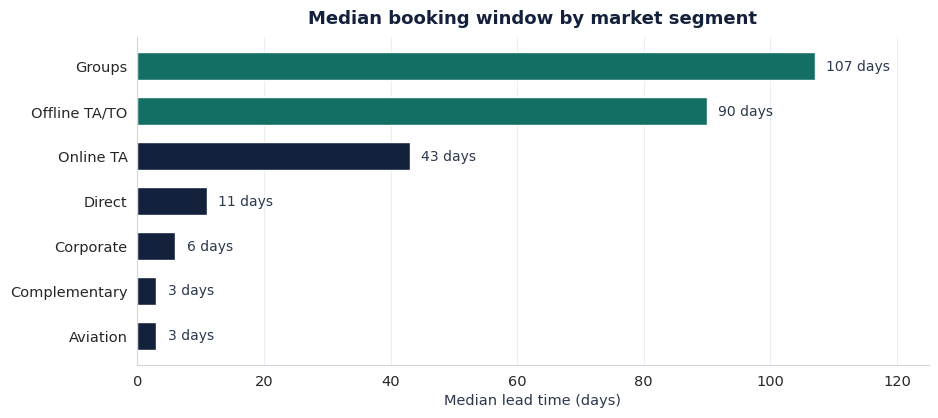

In [8]:
# ==============================================================================
# SECTION 08: MARKET SEGMENT PROFILE TABLE & MEDIAN BOOKING WINDOW CHART
# What we are doing:
#   1. Build the complete 7-segment profile table across all 75,166 stayed
#      bookings: Bookings, Share, Median lead time, Same-day share, Within 7 days
#      share, Over 180 days share, and Average ADR (EUR).
#   2. Compute the segment composition of all 17,844 bookings made within 7 days
#      (42.3% Online TA, 27.1% Direct, 14.0% Corporate, 10.0% Offline TA/TO)
#      and all 10,615 bookings made more than 180 days ahead (36.6% Offline TA/TO,
#      32.8% Online TA, 24.4% Groups).
#   3. Plot Figure 8: Horizontal bar chart of median booking window (days) by
#      market segment, highlighting long-lead segments (>= 90 days) in Teal.
# ==============================================================================

# 1. Build Complete 7-Segment Profile Pivot Table
seg_order = [
    "Online TA",
    "Offline TA/TO",
    "Direct",
    "Groups",
    "Corporate",
    "Complementary",
    "Aviation",
]
total_n = len(df_stayed)

profile_rows = []
for seg in seg_order:
  sub = df_stayed[df_stayed["market_segment"] == seg]
  profile_rows.append({
      "Segment": seg,
      "Bookings": f"{len(sub):,}",
      "Share": f"{len(sub) / total_n * 100:.1f}%",
      "Median lead": f"{sub['lead_time'].median():.0f} days",
      "Same-day": f"{(sub['lead_time'] == 0).mean() * 100:.1f}%",
      "Within 7 days": f"{(sub['lead_time'] <= 7).mean() * 100:.1f}%",
      "Over 180 days": f"{(sub['lead_time'] > 180).mean() * 100:.1f}%",
      "Avg ADR": f"EUR {sub['adr'].mean():.1f}",
      "_median_num": sub["lead_time"].median(),
  })

df_sec08 = pd.DataFrame(profile_rows)

print("--- SECTION 08: COMPLETE MARKET SEGMENT PROFILE TABLE ---")
print(df_sec08.drop(columns=["_median_num"]).to_string(index=False))

# 2. Composition Shares Within 7 Days and Over 180 Days
within_7_df = df_stayed[df_stayed["lead_time"] <= 7]
over_180_df = df_stayed[df_stayed["lead_time"] > 180]

w7_shares = (within_7_df["market_segment"].value_counts(normalize=True) * 100).round(1)
o180_shares = (over_180_df["market_segment"].value_counts(normalize=True) * 100).round(1)

print(f"\n--- SEGMENT SHARE OF BOOKINGS WITHIN 7 DAYS (n = {len(within_7_df):,}) ---")
for seg in ["Online TA", "Direct", "Corporate", "Offline TA/TO"]:
  print(f"{seg:<15} : {w7_shares[seg]:.1f}%")

print(f"\n--- SEGMENT SHARE OF BOOKINGS OVER 180 DAYS (n = {len(over_180_df):,}) ---")
for seg in ["Offline TA/TO", "Online TA", "Groups"]:
  print(f"{seg:<15} : {o180_shares[seg]:.1f}%")

# 3. Figure 8: Median Booking Window by Market Segment
fig8_order = [
    "Aviation",
    "Complementary",
    "Corporate",
    "Direct",
    "Online TA",
    "Offline TA/TO",
    "Groups",
]
df_fig8 = df_sec08.set_index("Segment").loc[fig8_order].reset_index()
bar_colors = [TEAL if m >= 90 else NAVY for m in df_fig8["_median_num"]]

fig8, ax8 = plt.subplots(figsize=(9.5, 4.3))
bars = ax8.barh(
    df_fig8["Segment"],
    df_fig8["_median_num"],
    color=bar_colors,
    height=0.62,
)

for bar, val in zip(bars, df_fig8["_median_num"]):
  ax8.text(
      val + 1.8,
      bar.get_y() + bar.get_height() / 2,
      f"{int(val)} days",
      va="center",
      ha="left",
      fontsize=10,
      color="#2b384e",
  )

ax8.set_title(
    "Median booking window by market segment",
    fontsize=13,
    fontweight="bold",
    color=NAVY,
    pad=10,
)
ax8.set_xlabel("Median lead time (days)", fontsize=10.5, color="#2b384e")
ax8.set_xlim(0, 125)
ax8.yaxis.grid(False)
ax8.xaxis.grid(True, color="#eaedf2", linewidth=0.8)
ax8.spines["top"].set_visible(False)
ax8.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("figure8_median_window_by_segment.png", dpi=300)
plt.show()

--- SECTION 09: ADR BY LEAD TIME BUCKET TABLE ---
     Lead time Bookings Share of bookings Share of total ADR   Avg ADR
      Same day    5,915              7.9%               6.5%  EUR 82.8
   1 to 7 days   11,929             15.9%              14.7%  EUR 92.4
  8 to 30 days   13,677             18.2%              19.0% EUR 104.6
 31 to 90 days   18,412             24.5%              25.5% EUR 103.9
91 to 180 days   14,618             19.4%              20.6% EUR 106.2
     181+ days   10,615             14.1%              13.7%  EUR 96.9


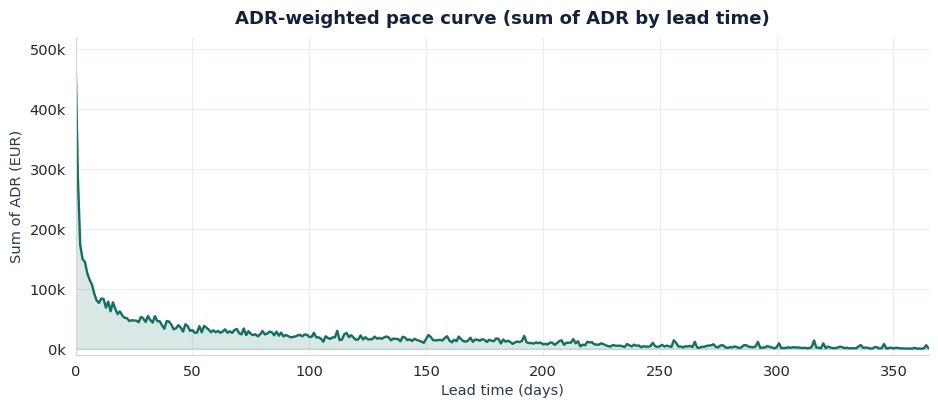

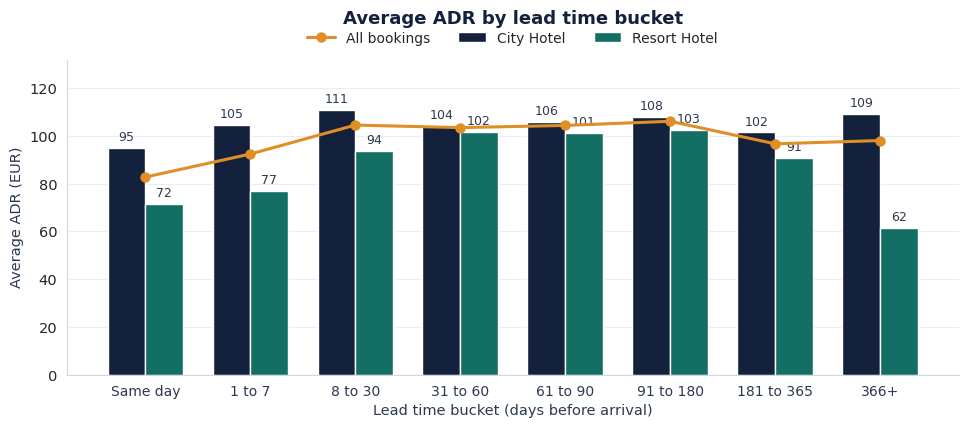

In [9]:
# ==============================================================================
# SECTION 09: ADR BY LEAD TIME (PACE CURVE, BUCKETED CHART & PIVOT TABLE)
# What we are doing:
#   1. Group all 75,166 stayed bookings into 6 lead-time windows (Same day,
#      1 to 7 days, 8 to 30 days, 31 to 90 days, 91 to 180 days, 181+ days)
#      and build the exact ADR pivot table: Bookings, Share of bookings,
#      Share of total ADR, and Average ADR (EUR).
#   2. Plot Figure 9: ADR-weighted pace curve showing the daily sum of ADR (EUR)
#      across lead times from 0 to 365 days.
#   3. Plot Figure 10: Average ADR across 8 granular lead-time buckets comparing
#      City Hotel (Navy bars), Resort Hotel (Teal bars), and All bookings (Amber line).
# ==============================================================================

# 1. Build Section 09 6-Bucket ADR Pivot Table
bins_table = [-1, 0, 7, 30, 90, 180, 9999]
labels_table = [
    "Same day",
    "1 to 7 days",
    "8 to 30 days",
    "31 to 90 days",
    "91 to 180 days",
    "181+ days",
]
df_stayed["lt_bucket_table"] = pd.cut(
    df_stayed["lead_time"], bins=bins_table, labels=labels_table
)

total_bookings = len(df_stayed)
total_adr_sum = df_stayed["adr"].sum()

adr_table_rows = []
for b in labels_table:
  sub = df_stayed[df_stayed["lt_bucket_table"] == b]
  adr_table_rows.append({
      "Lead time": b,
      "Bookings": f"{len(sub):,}",
      "Share of bookings": f"{len(sub) / total_bookings * 100:.1f}%",
      "Share of total ADR": f"{sub['adr'].sum() / total_adr_sum * 100:.1f}%",
      "Avg ADR": f"EUR {sub['adr'].mean():.1f}",
  })

df_sec09_table = pd.DataFrame(adr_table_rows)

print("--- SECTION 09: ADR BY LEAD TIME BUCKET TABLE ---")
print(df_sec09_table.to_string(index=False))

# 2. Figure 9: ADR-Weighted Pace Curve (0 to 365 days)
days_grid = np.arange(0, 366)
adr_sum_by_day = (
    df_stayed.groupby("lead_time")["adr"].sum().reindex(days_grid, fill_value=0)
)

fig9, ax9 = plt.subplots(figsize=(9.5, 4.2))
ax9.plot(days_grid, adr_sum_by_day.values / 1000.0, color=TEAL, linewidth=1.7)
ax9.fill_between(
    days_grid, adr_sum_by_day.values / 1000.0, color=TEAL, alpha=0.16
)

ax9.set_title(
    "ADR-weighted pace curve (sum of ADR by lead time)",
    fontsize=13,
    fontweight="bold",
    color=NAVY,
    pad=10,
)
ax9.set_xlabel("Lead time (days)", fontsize=10.5, color="#2b384e")
ax9.set_ylabel("Sum of ADR (EUR)", fontsize=10.5, color="#2b384e")
ax9.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}k"))
ax9.set_xlim(0, 365)
ax9.set_ylim(-10, 520)
ax9.spines["top"].set_visible(False)
ax9.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("figure9_adr_weighted_pace_curve.png", dpi=300)
plt.show()

# 3. Figure 10: Average ADR Across 8 Granular Lead-Time Buckets
bins_fig10 = [-1, 0, 7, 30, 60, 90, 180, 365, 9999]
labels_fig10 = [
    "Same day",
    "1 to 7",
    "8 to 30",
    "31 to 60",
    "61 to 90",
    "91 to 180",
    "181 to 365",
    "366+",
]
df_stayed["lt_bucket_fig10"] = pd.cut(
    df_stayed["lead_time"], bins=bins_fig10, labels=labels_fig10
)

all_adr = (
    df_stayed.groupby("lt_bucket_fig10", observed=False)["adr"]
    .mean()
    .reindex(labels_fig10)
)
city_adr = (
    df_stayed[df_stayed["hotel"] == "City Hotel"]
    .groupby("lt_bucket_fig10", observed=False)["adr"]
    .mean()
    .reindex(labels_fig10)
)
resort_adr = (
    df_stayed[df_stayed["hotel"] == "Resort Hotel"]
    .groupby("lt_bucket_fig10", observed=False)["adr"]
    .mean()
    .reindex(labels_fig10)
)

fig10, ax10 = plt.subplots(figsize=(9.8, 4.4))
x = np.arange(len(labels_fig10))
width = 0.36

rects_city = ax10.bar(
    x - width / 2, city_adr.values, width, color=NAVY, label="City Hotel"
)
rects_resort = ax10.bar(
    x + width / 2, resort_adr.values, width, color=TEAL, label="Resort Hotel"
)
ax10.plot(
    x,
    all_adr.values,
    color=AMBER,
    marker="o",
    markersize=6.5,
    linewidth=2.2,
    label="All bookings",
    zorder=5,
)

for rect in list(rects_city) + list(rects_resort):
  h = rect.get_height()
  ax10.text(
      rect.get_x() + rect.get_width() / 2,
      h + 1.8,
      f"{h:.0f}",
      ha="center",
      va="bottom",
      fontsize=9,
      color="#2b384e",
  )

ax10.set_title(
    "Average ADR by lead time bucket",
    fontsize=13,
    fontweight="bold",
    color=NAVY,
    pad=26,
)
ax10.set_xlabel(
    "Lead time bucket (days before arrival)", fontsize=10.5, color="#2b384e"
)
ax10.set_ylabel("Average ADR (EUR)", fontsize=10.5, color="#2b384e")
ax10.set_xticks(x)
ax10.set_xticklabels(labels_fig10, fontsize=10, color="#2b384e")
ax10.set_ylim(0, 132)
ax10.xaxis.grid(False)
ax10.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.13),
    ncol=3,
    frameon=False,
    fontsize=10,
)
ax10.spines["top"].set_visible(False)
ax10.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("figure10_avg_adr_by_lead_time_bucket.png", dpi=300)
plt.show()

--- SECTION 10: TOP 10 BUSIEST ARRIVAL DATES & PEAK BLOCKS ---
05 Dec 2015 | 255 bookings | Peak block:  42 Groups        (Resort) made  11 days out
24 Jun 2016 | 220 bookings | Peak block:  95 Offline TA/TO (City  ) made 192 days out
26 May 2016 | 213 bookings | Peak block: 122 Groups        (City  ) made 316 days out
06 Jun 2016 | 200 bookings | Peak block:  79 Offline TA/TO (City  ) made 118 days out
25 May 2017 | 190 bookings | Peak block:  45 Groups        (Resort) made 203 days out
25 Feb 2017 | 189 bookings | Peak block:  71 Groups        (City  ) made 134 days out
15 Oct 2015 | 188 bookings | Peak block:  82 Groups        (Resort) made 287 days out
24 Mar 2016 | 184 bookings | Peak block:  31 Offline TA/TO (Resort) made 136 days out
02 Oct 2015 | 183 bookings | Peak block:  90 Offline TA/TO (City  ) made 164 days out (note: 1 booking > 400d)
02 May 2016 | 181 bookings | Peak block:  26 Groups        (Resort) made 199 days out


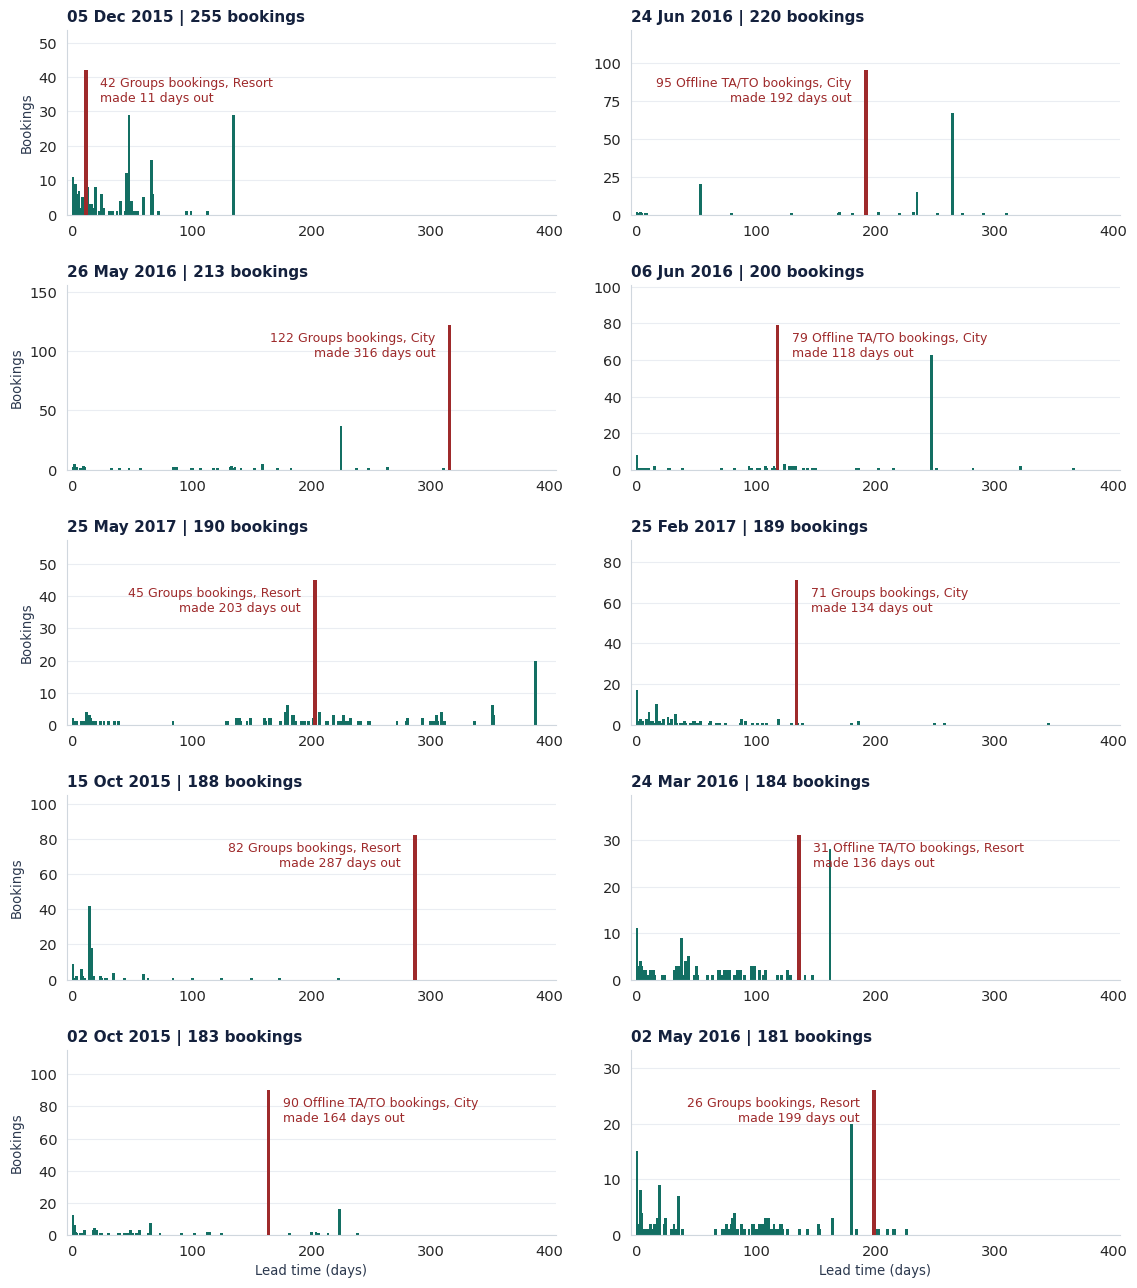

In [10]:
# ==============================================================================
# SECTION 10: TOP 10 BUSIEST ARRIVAL DATES & SINGLE-DAY BLOCK SPIKE GRID
# What we are doing:
#   1. Rank all arrival dates by total stayed bookings and select the Top 10
#      busiest arrival dates (ranging from 181 to 255 stayed bookings).
#   2. For each of the Top 10 dates, group by lead_time to find the largest
#      single-day block surge, its dominant market segment, and primary hotel.
#   3. Plot Figure 11: A 5x2 grid of daily lead-time bar charts (0 to 400 days),
#      colouring standard daily pickup in Teal and highlighting each date's
#      largest single-day block in Crimson with an inline annotation.
# ==============================================================================

# 1. Identify Top 10 Busiest Arrival Dates
top10_dates = (
    df_stayed.groupby("arrival_date").size().sort_values(ascending=False).head(10)
)

print("--- SECTION 10: TOP 10 BUSIEST ARRIVAL DATES & PEAK BLOCKS ---")
for dt, total_cnt in top10_dates.items():
  sub = df_stayed[df_stayed["arrival_date"] == dt]
  lt_counts = sub.groupby("lead_time").size()
  peak_lt = int(lt_counts.idxmax())
  peak_cnt = int(lt_counts.max())

  sub_block = sub[sub["lead_time"] == peak_lt]
  top_seg = sub_block["market_segment"].value_counts().idxmax()
  top_hotel = sub_block["hotel"].value_counts().idxmax().replace(" Hotel", "")
  beyond_400 = (sub["lead_time"] > 400).sum()

  note = f" (note: {beyond_400} booking > 400d)" if beyond_400 > 0 else ""
  print(
      f"{dt.strftime('%d %b %Y')} | {total_cnt:>3} bookings | "
      f"Peak block: {peak_cnt:>3} {top_seg:<13} ({top_hotel:<6}) "
      f"made {peak_lt:>3} days out{note}"
  )

# 2. Figure 11: 5x2 Small-Multiples Grid (Lead Time 0 to 400 Days)
fig11, axes = plt.subplots(5, 2, figsize=(11.5, 13.0))
axes = axes.flatten()

for idx, (dt, total_cnt) in enumerate(top10_dates.items()):
  ax = axes[idx]
  sub = df_stayed[df_stayed["arrival_date"] == dt]
  lt_counts = sub.groupby("lead_time").size()
  peak_lt = int(lt_counts.idxmax())
  peak_cnt = int(lt_counts.max())

  sub_block = sub[sub["lead_time"] == peak_lt]
  top_seg = sub_block["market_segment"].value_counts().idxmax()
  top_hotel = sub_block["hotel"].value_counts().idxmax().replace(" Hotel", "")

  # Plot regular pickup in Teal and largest single-day block in Crimson
  other_lt = lt_counts[lt_counts.index != peak_lt]
  ax.bar(
      other_lt.index,
      other_lt.values,
      width=2.4,
      color=TEAL,
      edgecolor="none",
  )
  ax.bar(
      [peak_lt],
      [peak_cnt],
      width=3.0,
      color=CRIMSON,
      edgecolor="none",
      zorder=4,
  )

  date_label = dt.strftime("%d %b %Y")
  ax.set_title(
      f"{date_label} | {total_cnt} bookings",
      loc="left",
      fontsize=11,
      fontweight="bold",
      color=NAVY,
      pad=6,
  )
  ax.set_xlim(-5, 405)
  ax.set_xticks([0, 100, 200, 300, 400])
  ax.set_ylim(0, max(peak_cnt * 1.28, 30))

  # Annotate largest block in Crimson
  ann_text = (
      f"{peak_cnt} {top_seg} bookings, {top_hotel}\nmade {peak_lt} days out"
  )
  if peak_lt < 180:
    ax.text(
        peak_lt + 12,
        peak_cnt * 0.96,
        ann_text,
        ha="left",
        va="top",
        fontsize=9,
        color=CRIMSON,
    )
  else:
    ax.text(
        peak_lt - 12,
        peak_cnt * 0.96,
        ann_text,
        ha="right",
        va="top",
        fontsize=9,
        color=CRIMSON,
    )

  if idx % 2 == 0:
    ax.set_ylabel("Bookings", fontsize=9.5, color="#2b384e")
  if idx >= 8:
    ax.set_xlabel("Lead time (days)", fontsize=9.5, color="#2b384e")

  ax.spines["top"].set_visible(False)
  ax.spines["right"].set_visible(False)
  ax.xaxis.grid(False)

plt.tight_layout(h_pad=1.8, w_pad=2.0)
plt.savefig("figure11_top10_arrival_dates.png", dpi=300)
plt.show()